# 任務 5：依科系分組與比較
目標：計算各組筆數、平均數及中位數，並正確解讀圖表。

**學生版**｜與教師版任務及小節編號一一對應

## 開始之前
姓名：＿田紹廷＿＿＿　學號：＿C114118141＿＿＿

本教材可以在 Colab 或 Jupyter 執行，請依序執行儲存格。每份任務的準備儲存格會在記憶體重新建立相同的模擬資料，不會覆寫 CSV。若要分析自己先前產生的 CSV，先上傳檔案，執行準備儲存格後再執行 `df = pd.read_csv("student_learning_data.csv")`；不同資料的驗證數字可能不同。

成績是人為公式生成，資料品質問題在計分後加入。結果只描述模擬資料，不能推論真實學生或證明因果。每個任務請先預測，執行後修改與驗證，最後用自己的話解釋。

### 學生操作方式
1. 先執行下一個完整的資料準備儲存格。每份任務可獨立執行；重啟環境後請由上而下重新執行。
2. 在每個小節的程式中，將 `___` 替換成符合題意的程式碼，並把 `# 學生註解` 改成自己的繁體中文解說（至少說明指定程式的輸入／處理／輸出）。`___` 是刻意留下的空格，完成前執行會報錯。
3. 先記錄預測，執行後完成驗證與解釋；再完成延伸練習。遇到困難可以使用小節專屬 AI 提示詞，仍須檢查、修改、執行與理解。
4. 在文字儲存格中填寫答案，保留程式、執行結果、圖表和 AI 使用紀錄。依教師指示交付已完成的 `.ipynb`。首次執行任務 1 的存檔程式會覆寫同名 practice_student_data.csv，請先確認或改檔名。


In [1]:
# 載入分析與繪圖套件；np、pd、plt 是慣用縮寫
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 固定種子及呼叫順序，使本課範例能重現
rng = np.random.default_rng(42)
n = 60  # 模擬學生人數
departments = ["資訊管理", "企業管理", "金融管理"]
# 字典每個鍵是欄位名稱，每個值提供 60 位學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)  # 把字典轉成資料表
noise = rng.normal(0, 5, n)  # 模擬其他未觀察的差異
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)  # 限制 0 到 100 分
df.loc[[5, 17], "sleep_hours"] = np.nan  # 成績算完後才加入缺失
df.loc[8, "screen_time_hours"] = 15.0  # 成績算完後才加入異常值
print("資料已準備：", df.shape)

資料已準備： (60, 7)


## 5.1 分組
`groupby` 把相同科系的列放在同一組；`count` 只算成績非缺失的資料。比較前應留意各組大小。
**預測：** 各組人數合計是多少？

### 學生練習 5.1：完成程式與註解

- **程式填空：** 補上依 department 分組，計算 quiz_score 的 count、mean、median。
- **註解任務：** 將程式中的兩處「學生註解」改寫為自己的說明；第一處解釋填空程式的輸入、處理與輸出，第二處解釋另一行程式的作用。
- **先預測：** 執行前，寫下你預期會看到什麼，或描述操作的效果。

**我的預測：**（請填寫）

**AI 求助提示詞（可直接複製）：**
> 我是 Python 初學者，正在完成資料分析任務 5.1。我的資料表叫 df，請教我如何補上依 department 分組，計算 quiz_score 的 count、mean、median。 請先說明使用的 pandas 或 matplotlib 語法和每個參數，再給我可替換 `___` 的一小段程式；不要假設我的執行結果。請提供一個核對方法，並提醒我如何用自己的話撰寫註解。


In [2]:
# 學生註解 1：請說明填空程式的輸入、處理與輸出
summary = df.groupby("department")["quiz_score"].agg(["count", "mean", "median"])
print(summary)
print("有效成績總數：", summary["count"].sum())
# 學生註解 2：請選另一行程式說明其作用


            count       mean  median
department                          
企業管理           21  80.666667    81.0
資訊管理           15  79.733333    80.0
金融管理           24  76.583333    76.5
有效成績總數： 60


### 驗證、解釋與延伸 5.1

**驗證與解釋：** 各組成績有效筆數加總是多少？哪一組平均最高？這是否代表科系造成差異？

**我的結果與解釋（引用實際輸出）：**（請填寫）

**延伸練習：** 依科系計算 study_hours 的 count 與 mean。 請在下一個程式儲存格完成，並加上自己的註解。

**延伸練習的預測與驗證：**（請填寫）

**AI 求助提示詞：**
> 請引導我完成這個延伸練習：依科系計算 study_hours 的 count 與 mean。 目前資料表名稱為 df。請分步解釋程式，建議我如何檢查輸出，不要捏造結果；如果需要使用前面建立的變數，請指出其前置步驟。


In [3]:
# 在此撰寫延伸練習與自己的註解


## 5.2 長條圖
每一柱代表某科系平均成績；標籤使用英文以避免環境中文字型缺失。圖表需對照數值表，不可單憑柱高推論因果。

### 學生練習 5.2：完成程式與註解

- **程式填空：** 補上取得各組平均成績並以 labels 更換索引標籤的運算。
- **註解任務：** 將程式中的兩處「學生註解」改寫為自己的說明；第一處解釋填空程式的輸入、處理與輸出，第二處解釋另一行程式的作用。
- **先預測：** 執行前，寫下你預期會看到什麼，或描述操作的效果。

**我的預測：**（請填寫）

**AI 求助提示詞（可直接複製）：**
> 我是 Python 初學者，正在完成資料分析任務 5.2。我的資料表叫 df，請教我如何補上取得各組平均成績並以 labels 更換索引標籤的運算。 請先說明使用的 pandas 或 matplotlib 語法和每個參數，再給我可替換 `___` 的一小段程式；不要假設我的執行結果。請提供一個核對方法，並提醒我如何用自己的話撰寫註解。


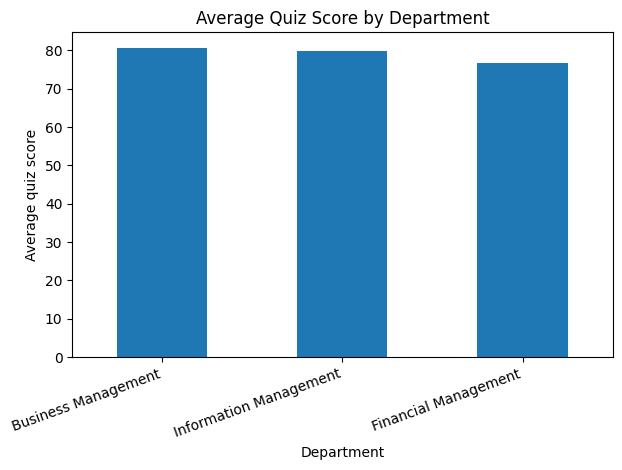

In [4]:
# 學生註解 1：請說明填空程式的輸入、處理與輸出
labels = {"資訊管理": "Information Management", "企業管理": "Business Management", "金融管理": "Financial Management"}
mean_scores = df.groupby("department")["quiz_score"].mean().rename(index=labels)
mean_scores.plot(kind="bar")
plt.title("Average Quiz Score by Department")
plt.xlabel("Department")
plt.ylabel("Average quiz score")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()
# 學生註解 2：請選另一行程式說明其作用


### 驗證、解釋與延伸 5.2

**驗證與解釋：** 圖上的柱高和 summary 的 mean 是否一致？標籤轉換是否改變原資料？

**我的結果與解釋（引用實際輸出）：**（請填寫）

**延伸練習：** 改以 median 畫長條圖，與平均數圖比較。 請在下一個程式儲存格完成，並加上自己的註解。

**延伸練習的預測與驗證：**（請填寫）

**AI 求助提示詞：**
> 請引導我完成這個延伸練習：改以 median 畫長條圖，與平均數圖比較。 目前資料表名稱為 df。請分步解釋程式，建議我如何檢查輸出，不要捏造結果；如果需要使用前面建立的變數，請指出其前置步驟。


In [ ]:
# 在此撰寫延伸練習與自己的註解


## 5.3 分組結果的限制
科系由程式隨機分配，計分公式沒有科系欄位；即使平均數不同，也不能宣稱科系造成成績差異。

### 學生練習 5.3：完成程式與註解

- **程式填空：** 補上統計各科系資料列數的運算。
- **註解任務：** 將程式中的兩處「學生註解」改寫為自己的說明；第一處解釋填空程式的輸入、處理與輸出，第二處解釋另一行程式的作用。
- **先預測：** 執行前，寫下你預期會看到什麼，或描述操作的效果。

**我的預測：**（請填寫）

**AI 求助提示詞（可直接複製）：**
> 我是 Python 初學者，正在完成資料分析任務 5.3。我的資料表叫 df，請教我如何補上統計各科系資料列數的運算。 請先說明使用的 pandas 或 matplotlib 語法和每個參數，再給我可替換 `___` 的一小段程式；不要假設我的執行結果。請提供一個核對方法，並提醒我如何用自己的話撰寫註解。


In [5]:
# 學生註解 1：請說明填空程式的輸入、處理與輸出
print(df["department"].value_counts())
# 學生註解 2：請選另一行程式說明其作用


department
金融管理    24
企業管理    21
資訊管理    15
Name: count, dtype: int64


### 驗證、解釋與延伸 5.3

**驗證與解釋：** 各組有幾筆？為何比較平均值前要留意樣本數？

**我的結果與解釋（引用實際輸出）：**（請填寫）

**延伸練習：** 將各組筆數加總，和 len(df) 核對。 請在下一個程式儲存格完成，並加上自己的註解。

**延伸練習的預測與驗證：**（請填寫）

**AI 求助提示詞：**
> 請引導我完成這個延伸練習：將各組筆數加總，和 len(df) 核對。 目前資料表名稱為 df。請分步解釋程式，建議我如何檢查輸出，不要捏造結果；如果需要使用前面建立的變數，請指出其前置步驟。


In [6]:
# 在此撰寫延伸練習與自己的註解


## 任務交付與 AI 使用紀錄

完成本任務的三個小節，儲存含輸出的 Notebook，依教師指定的方式繳交。任務 8 另需完成 8.3 的完整分析報告及其佐證圖表。

- 使用的 AI 提示詞（未使用請填「未使用」）：
- AI 建議中我修改或拒絕的一處及原因：
- 遇到的錯誤或疑問、修正與驗證方式：
- 本任務一項有數據支持的發現及對應儲存格：
- 一項資料或推論限制：

**交付前檢核：** 已填完程式空格與註解；已填寫預測、驗證、解釋與延伸；已由上到下執行並確認圖表和數字與文字一致。
